In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Generating a Nested SBM

In [5]:
def generate_nested_block_matrix(num_levels, num_blocks_per_level, p_in_list, p_out):
    """
    Generate a nested SBM probability matrix with level-specific intra-block probabilities.

    Args:
        num_levels (int): Number of hierarchical levels.
        num_blocks_per_level (list of int): Number of blocks at each level.
        p_in_list (list of float): List of intra-block probabilities, one for each level.
        p_out (float): Probability of inter-block connections.

    Returns:
        np.ndarray: Nested block probability matrix.
    """
    if len(p_in_list) != num_levels:
        raise ValueError("Length of p_in_list must match num_levels.")
    
    # Calculate the total number of blocks at the lowest level
    total_blocks = np.prod(num_blocks_per_level)
    
    # Initialize the probability matrix with inter-block probability
    prob_matrix = np.full((total_blocks, total_blocks), p_out)
    
    # Iterate through each level to apply the nested structure
    block_size = total_blocks
    for level, (num_blocks, p_in) in enumerate(zip(num_blocks_per_level, p_in_list)):
        block_size //= num_blocks  # Determine the size of blocks at this level
        for i in range(0, total_blocks, block_size):
            for j in range(0, total_blocks, block_size):
                if i == j:  # Intra-block connections at this level
                    prob_matrix[i:i+block_size, j:j+block_size] = p_in
    
    return prob_matrix

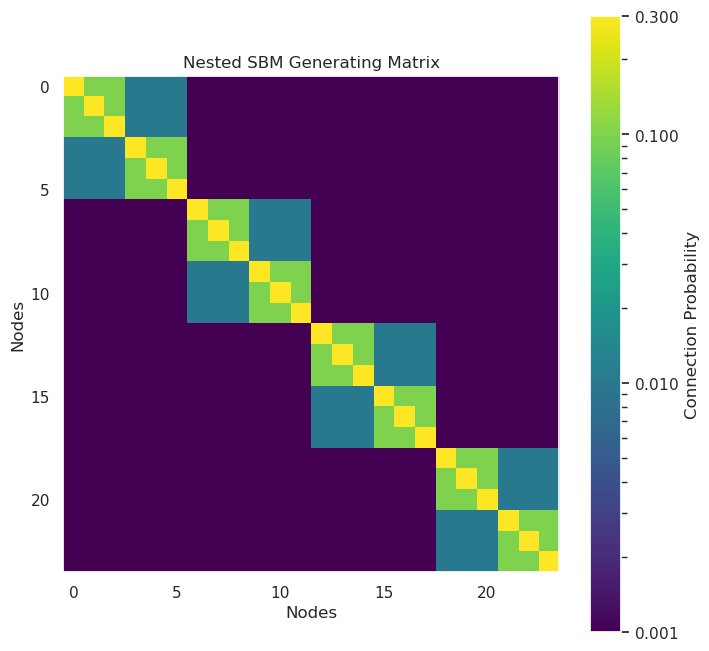

In [15]:
# Parameters
num_levels = 3
num_blocks_per_level = [4, 2, 3]  # Hierarchy: Level 1 = 4 blocks, Level 2 = 2 blocks per block, Level 3 = 2
p_ins = [0.01,0.1,0.3]
p_out = 0.001

# Generate the nested block matrix
prob_matrix = generate_nested_block_matrix(num_levels, num_blocks_per_level, p_ins, p_out)

# Visualize the matrix
from matplotlib.colors import LogNorm
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(prob_matrix, cmap='viridis', interpolation='none', norm=LogNorm(vmin=0.001, vmax=0.3), aspect='equal')
t = [0.001, 0.01, 0.1, 0.3]
plt.colorbar(im,ticks=t,format="$%.3f$",label="Connection Probability")
plt.title("Nested SBM Generating Matrix")
plt.xlabel("Nodes")
plt.ylabel("Nodes")
plt.grid(False)
plt.savefig("./figures/nested_sbm_block_structure.svg",
            dpi = 1000) # CONVERT TO PDF BY HAND!
plt.show()
plt.close()

In [7]:
from graph_tool.generation import generate_sbm
from graph_tool.draw import sfdp_layout, graph_draw

def nested_sbm_to_nx(prob_matrix, group_membership, directed=False, visualize=False, image_name="graph.png"):
    """
    Wrapper to generate a nested SBM graph using graph-tool, convert it to NetworkX, and optionally visualize it.

    Args:
        prob_matrix (np.ndarray): Block probability matrix for the SBM.
        group_membership (list or np.ndarray): List indicating group membership for each node.
        directed (bool): Whether the graph should be directed. Default is False.
        visualize (bool): Whether to generate an image of the graph. Default is False.
        image_name (str): Filename for the visualization output. Default is 'graph.png'.

    Returns:
        nx_graph (networkx.Graph or networkx.DiGraph): Converted NetworkX graph.
    """

    # Scale probs matrix to reflect block sizes
    unique_blocks, counts = np.unique(group_membership, return_counts=True)
    block_sizes = {block: count for block, count in zip(unique_blocks, counts)}

    scaled_probs = np.zeros_like(prob_matrix)
    for i in range(prob_matrix.shape[0]):
        for j in range(prob_matrix.shape[1]):
            scaled_probs[i, j] = prob_matrix[i, j] * block_sizes[i] * block_sizes[j]
    
    # Step 1: Generate the graph using graph-tool
    g_gt = generate_sbm(b=group_membership, probs=scaled_probs, directed=directed)
    
    # Step 2: Convert the graph-tool graph to a NetworkX graph
    if directed:
        nx_graph = nx.DiGraph()
    else:
        nx_graph = nx.Graph()
    
    # Add nodes to NetworkX graph
    nx_graph.add_nodes_from(range(g_gt.num_vertices()))
    
    # Add edges with weights (if applicable)
    for e in g_gt.edges():
        source = int(e.source())
        target = int(e.target())
        nx_graph.add_edge(source, target)

    # Step 3: Optionally visualize the graph using graph-tool
    if visualize:
        pos = sfdp_layout(g_gt)  # Layout algorithm
        graph_draw(g_gt, pos, output_size=(500, 500))
        print(f"Graph visualization saved as {image_name}")
    
    return nx_graph

In [8]:
def calculate_block_membership(num_nodes, num_blocks_per_level):
    """
    Calculate group membership for nodes to match specified hierarchical block sizes.

    Args:
        num_nodes (int): Total number of nodes in the network.
        num_blocks_per_level (list of int): Number of blocks at each level.

    Returns:
        list: Group membership list for all nodes.
    """
    # Total number of lowest-level blocks
    total_lowest_blocks = np.prod(num_blocks_per_level)
    
    # Determine base size of each lowest-level block
    base_block_size = num_nodes // total_lowest_blocks
    remainder = num_nodes % total_lowest_blocks  # Handle any leftover nodes

    group_membership = []
    current_index = 0

    # Assign nodes to blocks hierarchically
    def assign_nodes_recursive(level, start_index, block_size):
        nonlocal current_index
        num_blocks = num_blocks_per_level[level]
        sub_block_size = block_size // num_blocks

        for b in range(num_blocks):
            if level == len(num_blocks_per_level) - 1:  # Lowest level
                size = sub_block_size
                # Distribute remainder nodes evenly to the lowest-level blocks
                if current_index < remainder:
                    size += 1
                group_membership.extend([current_index] * size)
                current_index += 1
            else:
                assign_nodes_recursive(level + 1, start_index, sub_block_size)

    # Start recursive assignment
    assign_nodes_recursive(0, 0, num_nodes)
    return group_membership

In [13]:
# Example nested SBM probability matrix (as from earlier)
num_levels = 3
num_blocks_per_level = [4, 2, 3]  # Hierarchy: Level 1 = 4 blocks, Level 2 = 2 blocks per block, Level 3 = 2
p_ins = [0.01,0.1,0.3]
p_out = 0.001

# Generate the probability matrix
prob_matrix = generate_nested_block_matrix(num_levels, num_blocks_per_level, p_ins, p_out)
    
# Example group membership: groups for all nodes
num_nodes = 1000  # Total network size

# Generate group membership
group_membership = calculate_block_membership(num_nodes, num_blocks_per_level)

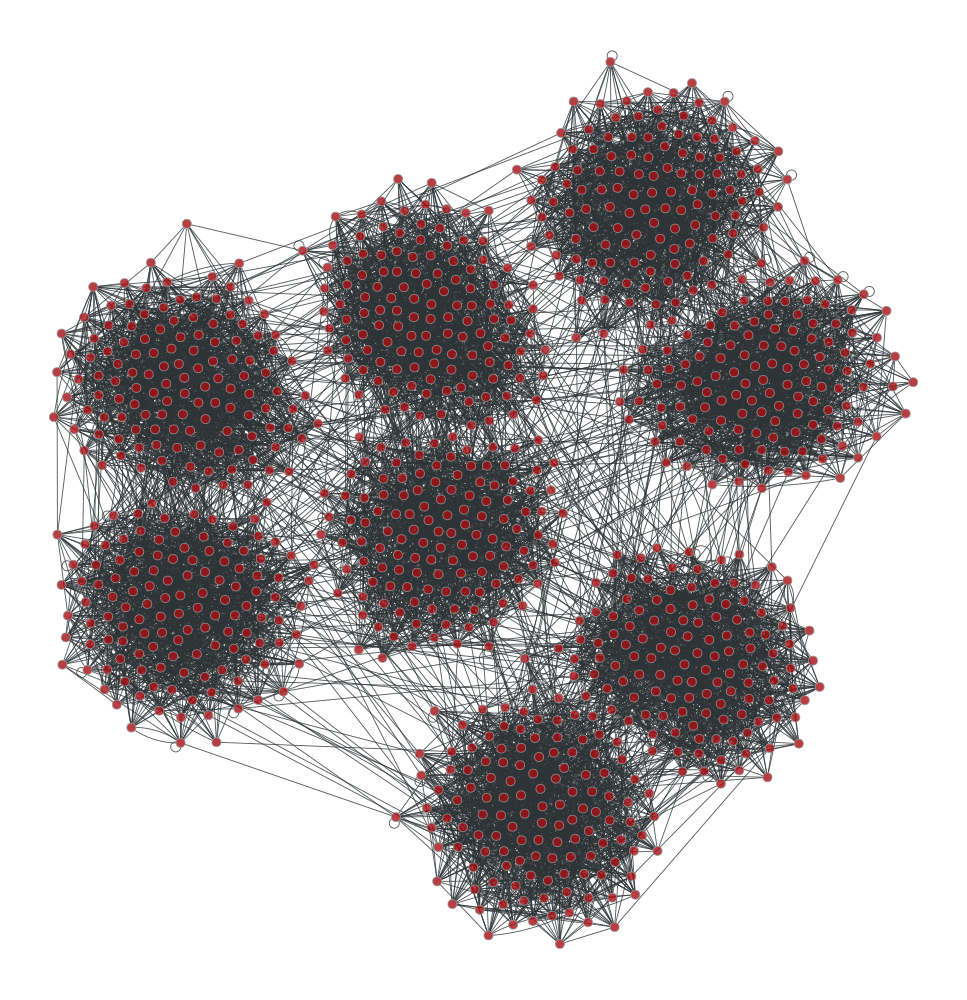

Graph visualization saved as None
Number of nodes in NetworkX graph: 1000
Number of edges in NetworkX graph: 10413


In [14]:
# Call the wrapper function
nx_graph = nested_sbm_to_nx(prob_matrix, group_membership, directed=False, visualize=True, image_name=None)

# Check the result
print("Number of nodes in NetworkX graph:", nx_graph.number_of_nodes())
print("Number of edges in NetworkX graph:", nx_graph.number_of_edges())

In [15]:
G = nx_graph

In [16]:
nx.write_graphml(G, "test_networks/nested_sbm.graphml")

# Init Fitter

In [4]:
filename = './test_networks/nested_sbm.graphml'
G = nx.read_graphml(filename)

In [5]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.768038
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:15.269078


In [6]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 10413},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 181143},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 9265},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 923414},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 1247},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 2843744},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 407591},
 {'name

# Grid Search

In [7]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,11]},
                {'m': 3,  'k': [1,8]},
                {'m': 5,  'k': [1,6]},
                {'m': 7,  'k': [1,5]}],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-02-20 16:36:53,923] A new study created in memory with name: no-name-60320b32-4180-4e07-9737-7385af70749a


Grid Search requires 10 trials...


[I 2025-02-20 16:37:04,161] Trial 0 finished with value: 2.789326066251534 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 2.789326066251534.
[I 2025-02-20 16:37:24,572] Trial 1 finished with value: 4.281488613617172 and parameters: {'m': 2, 'k': 9}. Best is trial 0 with value: 2.789326066251534.
[I 2025-02-20 16:37:33,740] Trial 2 finished with value: 4.1619746221429335 and parameters: {'m': 2, 'k': 5}. Best is trial 0 with value: 2.789326066251534.
[I 2025-02-20 16:38:26,377] Trial 3 finished with value: 4.987239207885634 and parameters: {'m': 2, 'k': 10}. Best is trial 0 with value: 2.789326066251534.
[I 2025-02-20 16:38:36,949] Trial 4 finished with value: 3.141729700498018 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 2.789326066251534.
[I 2025-02-20 16:38:47,770] Trial 5 finished with value: 2.921383399422273 and parameters: {'m': 2, 'k': 7}. Best is trial 0 with value: 2.789326066251534.
[I 2025-02-20 16:38:59,554] Trial 6 finished with value: 2.623

Grid Search requires 7 trials...


[I 2025-02-20 16:45:16,447] Trial 0 finished with value: 5.051748502113148 and parameters: {'m': 3, 'k': 7}. Best is trial 0 with value: 5.051748502113148.
[I 2025-02-20 16:45:32,243] Trial 1 finished with value: 2.924847019313998 and parameters: {'m': 3, 'k': 3}. Best is trial 1 with value: 2.924847019313998.
[I 2025-02-20 16:45:46,443] Trial 2 finished with value: 2.8633508873606566 and parameters: {'m': 3, 'k': 2}. Best is trial 2 with value: 2.8633508873606566.
[I 2025-02-20 16:46:01,561] Trial 3 finished with value: 2.4956404437907915 and parameters: {'m': 3, 'k': 4}. Best is trial 3 with value: 2.4956404437907915.
[I 2025-02-20 16:46:21,255] Trial 4 finished with value: 2.103458895490706 and parameters: {'m': 3, 'k': 1}. Best is trial 4 with value: 2.103458895490706.
[I 2025-02-20 16:46:58,943] Trial 5 finished with value: 3.4841996306718004 and parameters: {'m': 3, 'k': 6}. Best is trial 4 with value: 2.103458895490706.
[I 2025-02-20 16:47:16,045] Trial 6 finished with value: 2.

Grid Search requires 5 trials...


[I 2025-02-20 16:48:10,101] Trial 0 finished with value: 2.464486700394497 and parameters: {'m': 5, 'k': 3}. Best is trial 0 with value: 2.464486700394497.
[I 2025-02-20 16:49:03,336] Trial 1 finished with value: 2.671226296962285 and parameters: {'m': 5, 'k': 1}. Best is trial 0 with value: 2.464486700394497.
[I 2025-02-20 16:50:01,975] Trial 2 finished with value: 2.5968829986173336 and parameters: {'m': 5, 'k': 2}. Best is trial 0 with value: 2.464486700394497.
[I 2025-02-20 16:51:28,687] Trial 3 finished with value: 2.100554697686302 and parameters: {'m': 5, 'k': 4}. Best is trial 3 with value: 2.100554697686302.
[I 2025-02-20 17:16:54,588] Trial 4 finished with value: 2.4919519012543963 and parameters: {'m': 5, 'k': 5}. Best is trial 3 with value: 2.100554697686302.
[I 2025-02-20 17:16:54,590] A new study created in memory with name: no-name-6defae2c-9af7-4129-8e5a-cc9b5157b5a0


Grid Search requires 4 trials...


[I 2025-02-20 17:20:17,805] Trial 0 finished with value: 2.3368085330126416 and parameters: {'m': 7, 'k': 3}. Best is trial 0 with value: 2.3368085330126416.
[I 2025-02-20 18:02:22,326] Trial 1 finished with value: 1.9091713743815097 and parameters: {'m': 7, 'k': 4}. Best is trial 1 with value: 1.9091713743815097.
[I 2025-02-20 18:05:08,189] Trial 2 finished with value: 2.032284220260206 and parameters: {'m': 7, 'k': 2}. Best is trial 1 with value: 1.9091713743815097.
[I 2025-02-20 18:06:52,176] Trial 3 finished with value: 2.7683227514973496 and parameters: {'m': 7, 'k': 1}. Best is trial 1 with value: 1.9091713743815097.


Best parameters:  {'m': 7, 'k': 4}
Best energy:  4.123644269979627
Best KL-divergence:  0.024979192833711018
Best KLD augumented energy: 1.9091713743815097
Best P matrix:
 [[0.87833512 0.01593047 0.16267386 0.16794092 0.12786413 0.79178117
  0.91876695]
 [0.01593047 0.64340722 0.39656012 0.85380059 0.46650238 0.79286723
  0.83385682]
 [0.16267386 0.39656012 0.67158449 0.20219159 0.7586916  0.85142171
  0.81517312]
 [0.16794092 0.85380059 0.20219159 0.08845058 0.71343405 0.53192145
  0.83823224]
 [0.12786413 0.46650238 0.7586916  0.71343405 0.15585885 0.39859502
  0.7000851 ]
 [0.79178117 0.79286723 0.85142171 0.53192145 0.39859502 0.55897382
  0.73087121]
 [0.91876695 0.83385682 0.81517312 0.83823224 0.7000851  0.73087121
  0.80139796]]
Best l vector:
 [0.35817114 0.32704244 0.2203566  0.04930653 0.04001408 0.00367887
 0.00162384]


Energy: 6.158122754572588
KL-divergence: 0.04468621687241042
KLD augumented energy: 3.8358412615737585
[[0.52582947 0.10978333]
 [0.10978333 0.83633954]]
[0.59945717 0.40054283]


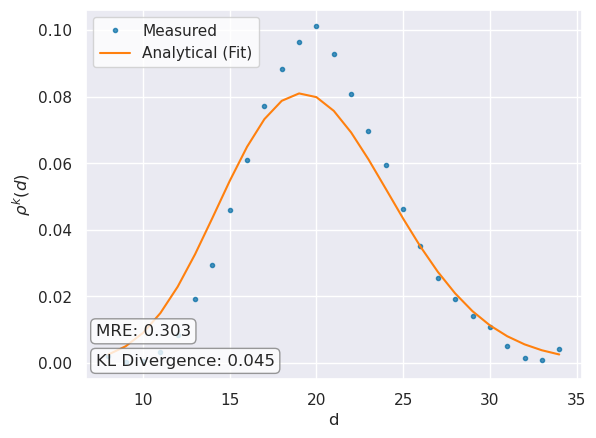

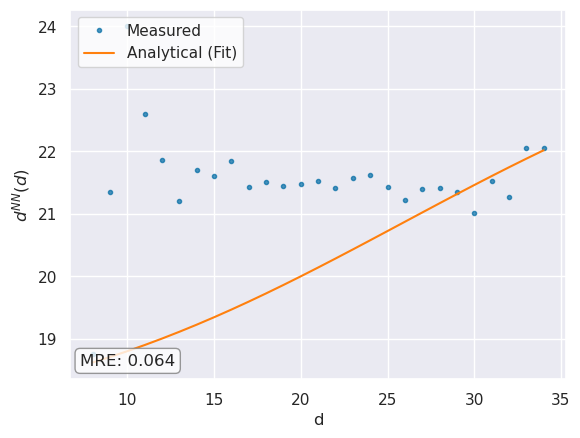

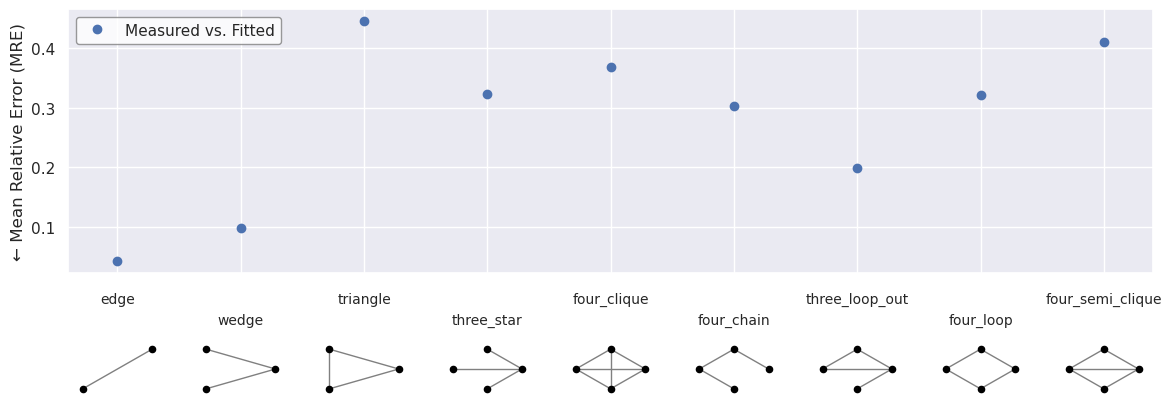

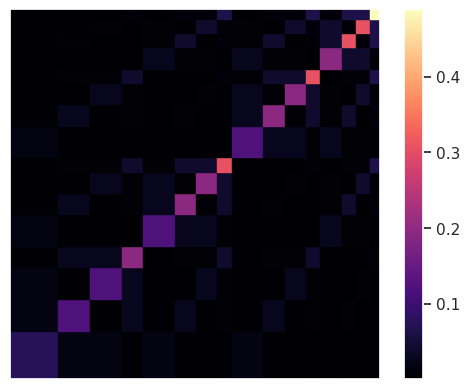

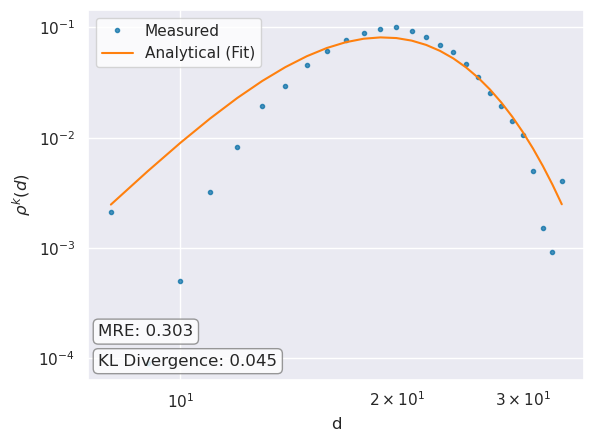

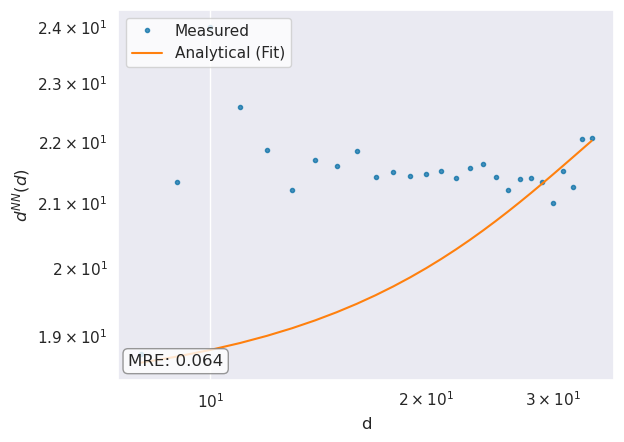

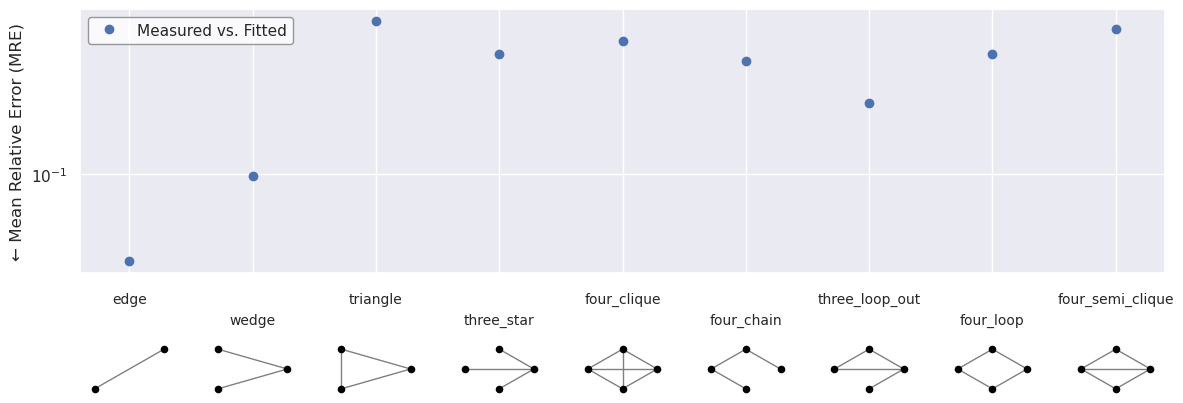

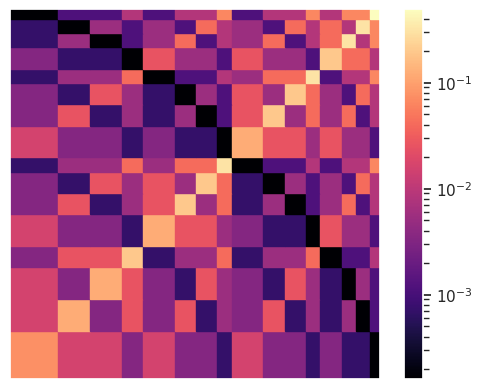

In [8]:
mfnf.find_P_l(m = 2, k = 4, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_2_4_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_2_4_plot_log.pdf"
)

#### Looking at 'second best' m-k pairs from the grid search

Energy: 4.1821652000105
KL-divergence: 0.017349788280368178
KLD augumented energy: 1.97334040257552
[[0.59383835 0.07522381 0.63465752]
 [0.07522381 0.80313534 0.02269267]
 [0.63465752 0.02269267 0.59296122]]
[0.56910206 0.41111216 0.01978578]


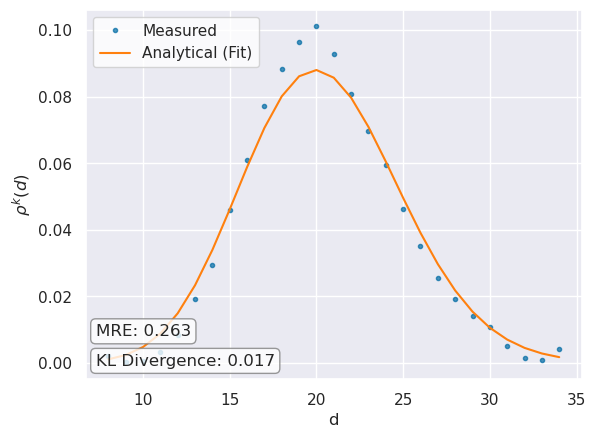

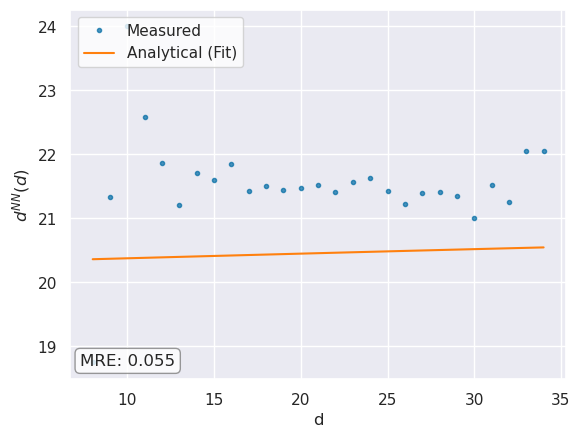

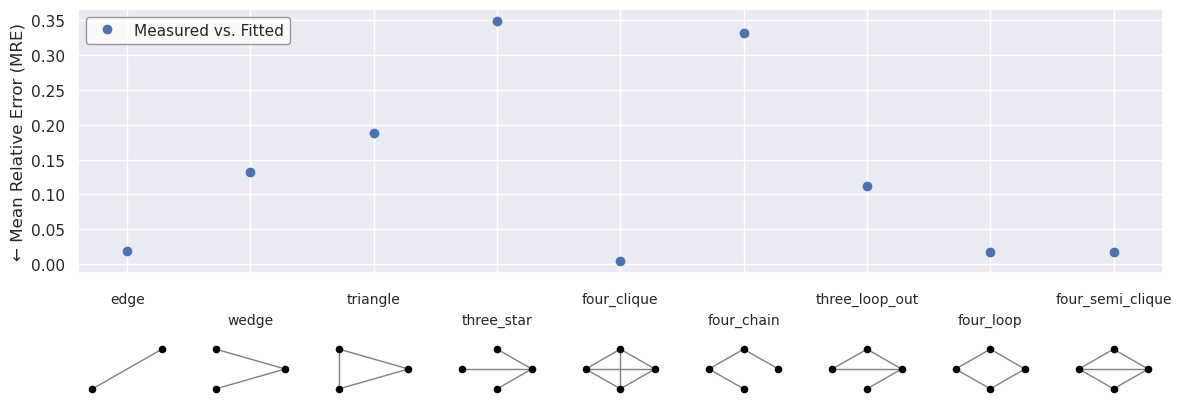

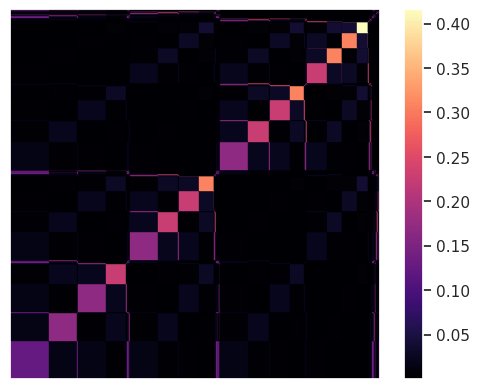

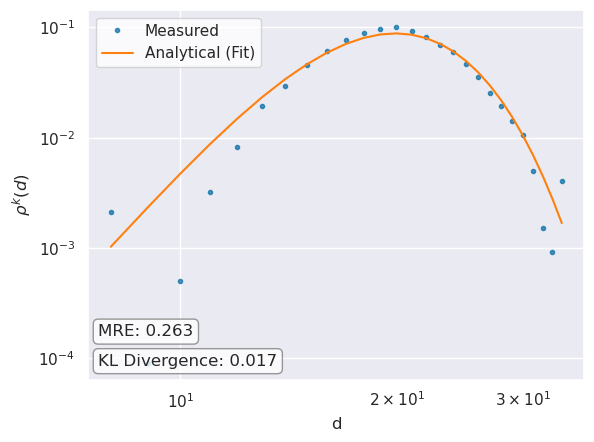

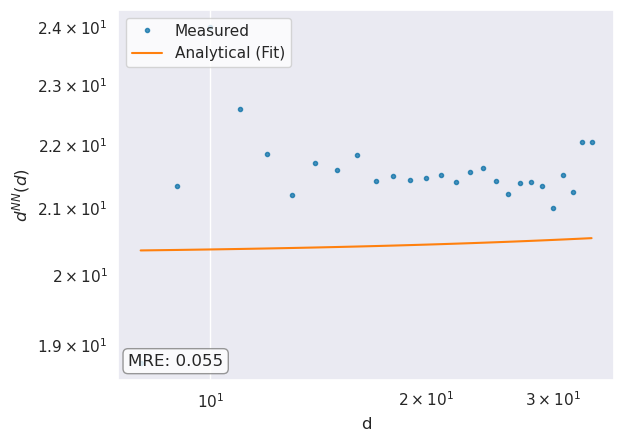

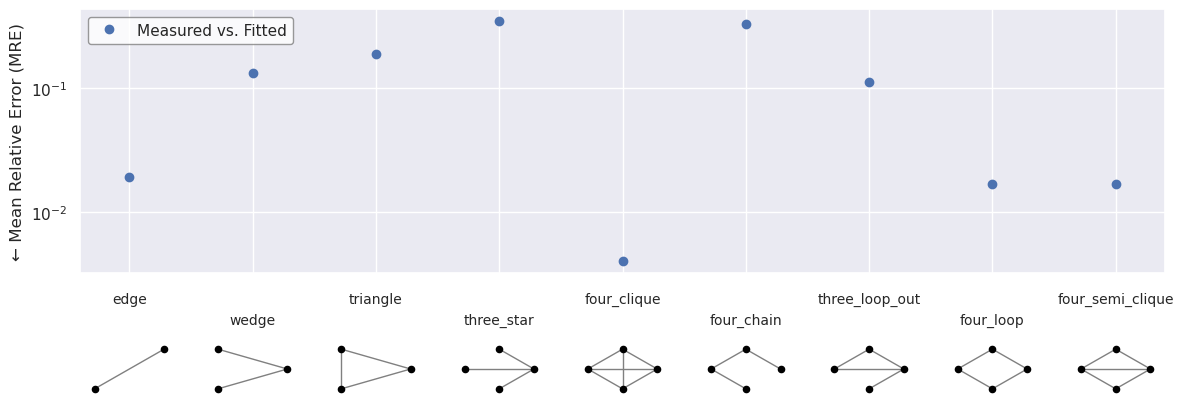

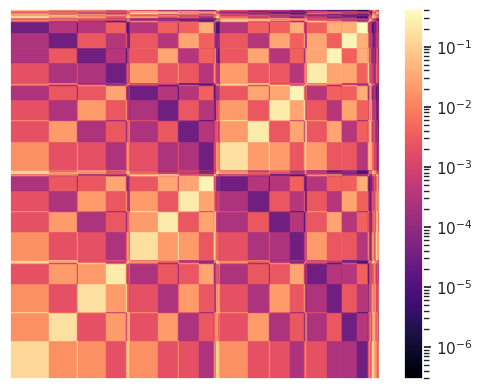

In [9]:
mfnf.find_P_l(m = 3, k = 4, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_3_4_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_3_4_plot_log.pdf"
)

Energy: 4.4677474782472535
KL-divergence: 0.02000611163888867
KLD augumented energy: 2.2569719832827357
[[7.31956868e-01 9.96137122e-02 7.32404478e-01 2.86685386e-01
  9.99999962e-01]
 [9.96137122e-02 8.91131089e-01 2.83712280e-01 6.16857711e-01
  9.99999991e-01]
 [7.32404478e-01 2.83712280e-01 2.86778237e-08 6.93974513e-01
  9.99998645e-01]
 [2.86685386e-01 6.16857711e-01 6.93974513e-01 9.99999748e-01
  3.04544575e-01]
 [9.99999962e-01 9.99999991e-01 9.99998645e-01 3.04544575e-01
  3.18065312e-01]]
[4.90711036e-01 4.22216350e-01 6.37125247e-02 2.30410770e-02
 3.19012312e-04]


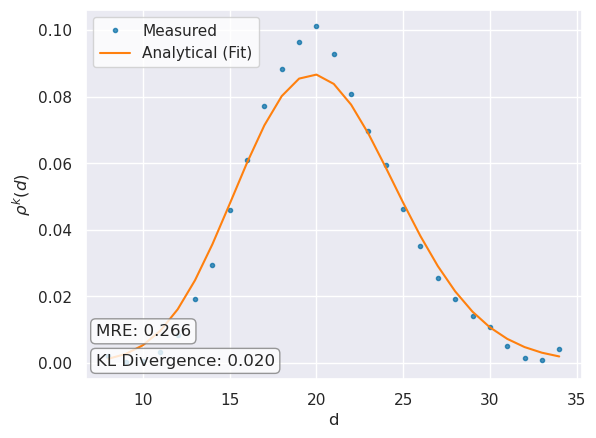

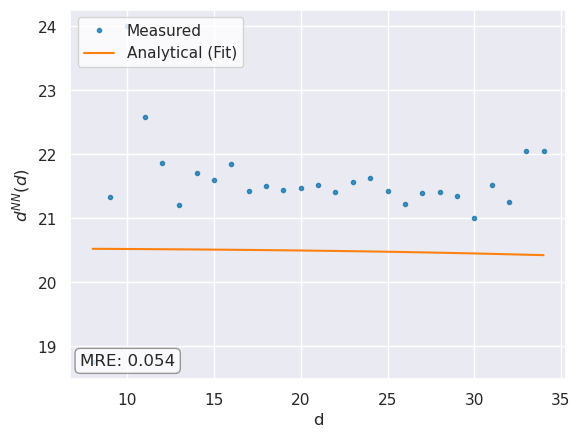

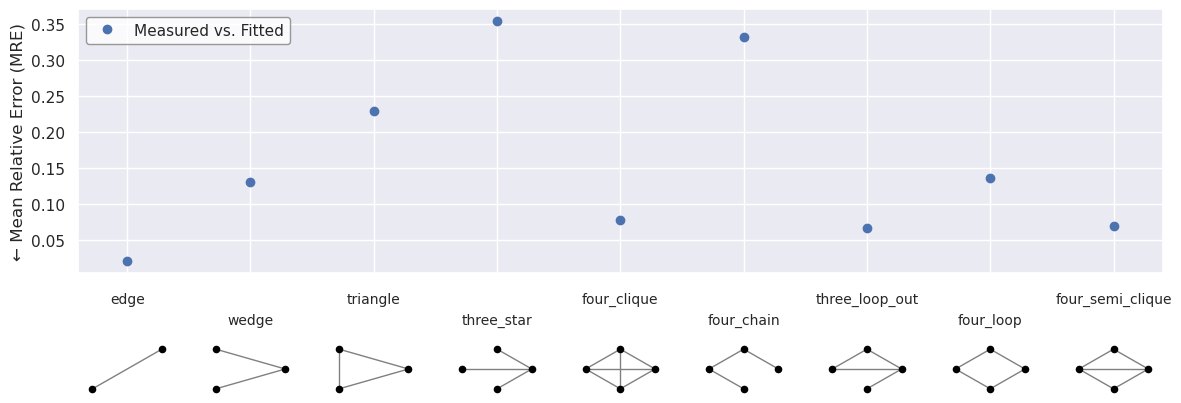

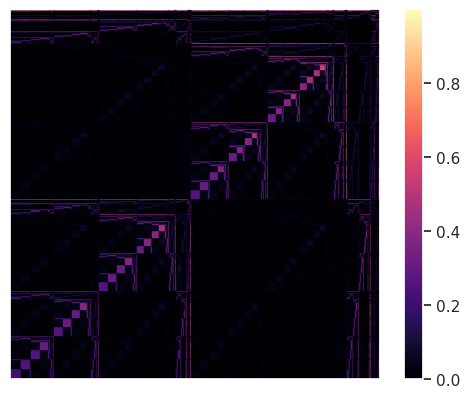

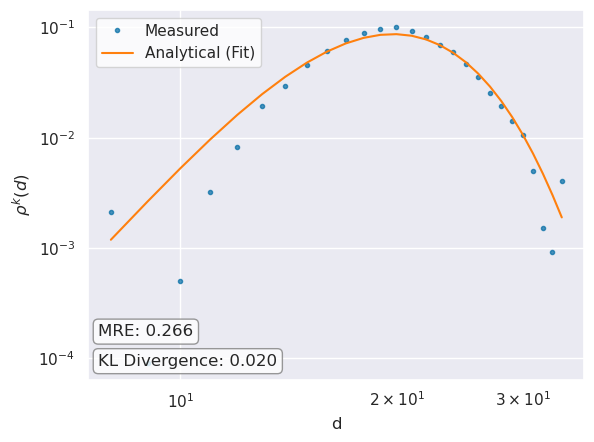

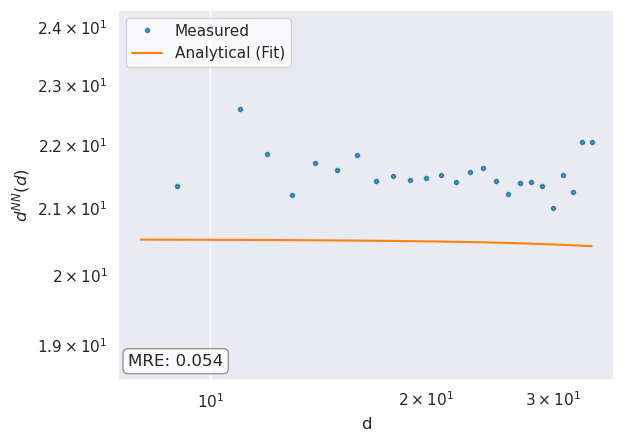

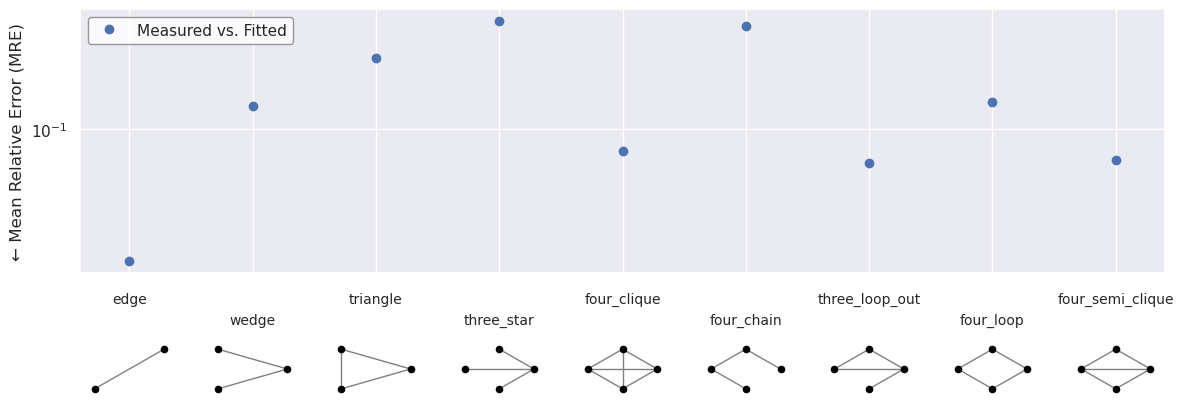

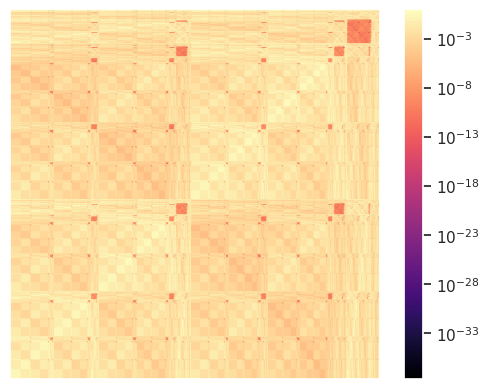

In [10]:
mfnf.find_P_l(m = 5, k = 5, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_5_5_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_5_5_plot_log.pdf"
)

Energy: 4.013342018515322
KL-divergence: 0.018838178979692474
KLD augumented energy: 1.9213094079832163
[[0.7675402  0.01755295 0.15086777 0.33352669 0.30501618 0.16977803
  0.81947699]
 [0.01755295 0.67294625 0.67612769 0.31840153 0.46027438 0.5401127
  0.6187031 ]
 [0.15086777 0.67612769 0.20181918 0.5440861  0.22962005 0.48512543
  0.70088615]
 [0.33352669 0.31840153 0.5440861  0.5974856  0.51179941 0.50496621
  0.86212851]
 [0.30501618 0.46027438 0.22962005 0.51179941 0.58958401 0.81206591
  0.24678159]
 [0.16977803 0.5401127  0.48512543 0.50496621 0.81206591 0.00574684
  0.92854648]
 [0.81947699 0.6187031  0.70088615 0.86212851 0.24678159 0.92854648
  0.11087833]]
[0.41846096 0.36132972 0.1310235  0.0381794  0.02319423 0.01930066
 0.00851154]


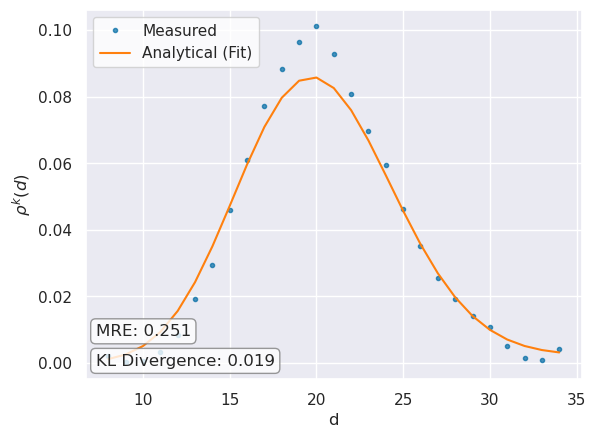

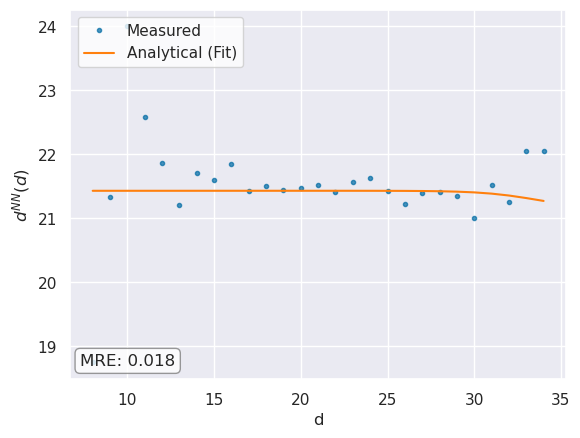

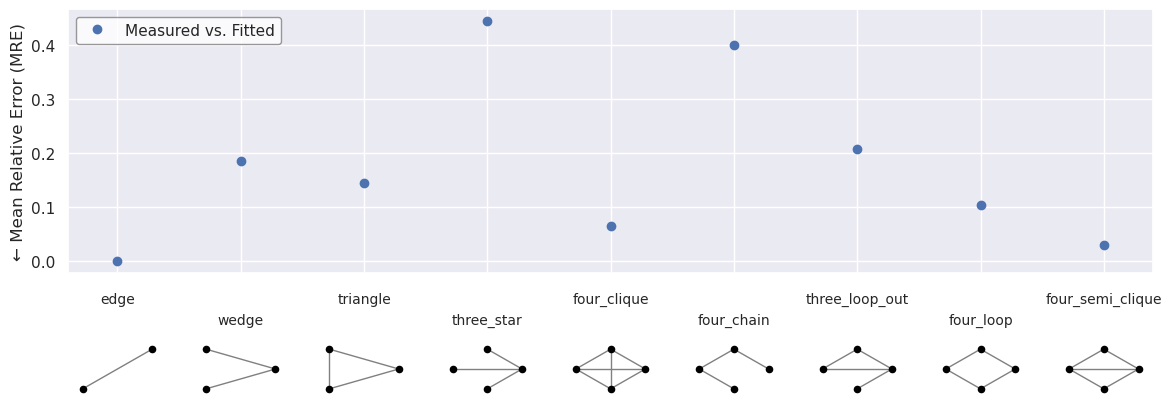

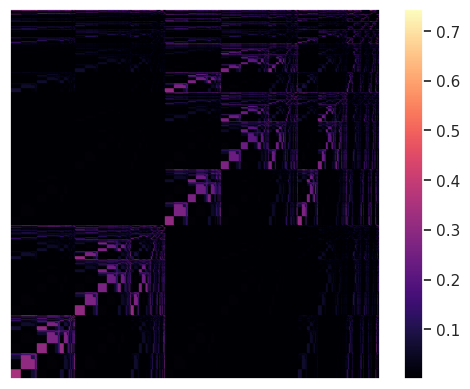

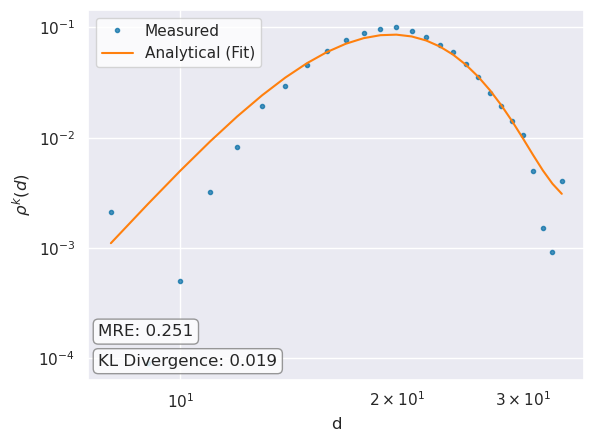

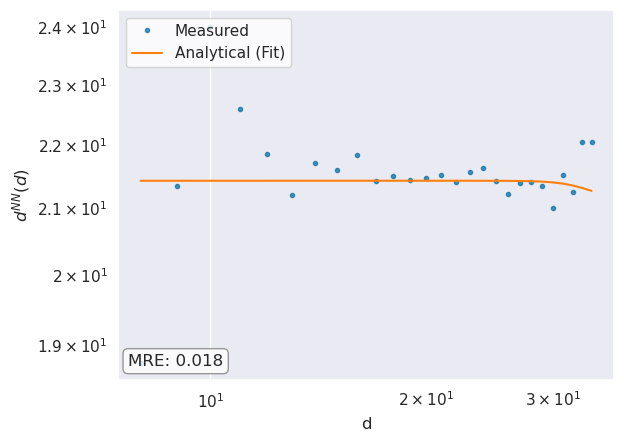

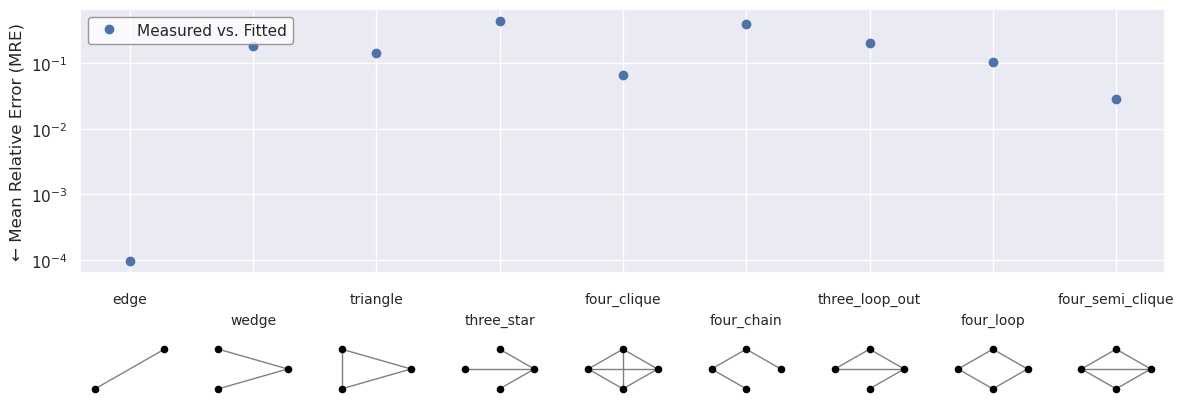

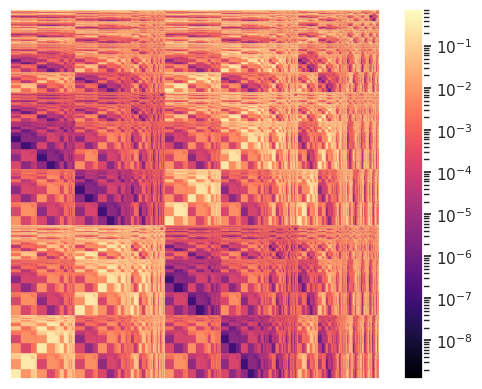

In [13]:
mfnf.find_P_l(m = 7, k = 4, one_shot=True)
print(mfnf.P)
print(mfnf.l)
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_7_4_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_7_4_plot_log.pdf"
)

In [12]:
import pickle
with open('./test_networks/nested_sbm_mfnf.pkl', 'wb') as f:
    pickle.dump(mfnf, f)

# Bootstrapping

In [28]:
mfnf.find_P_l(m = 2, k = 4, one_shot=True)

Energy: 4.159931246336172
KL-divergence: 0.017127583612420123
KLD augumented energy: 1.959318509391881


In [29]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'mean'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [10:34<00:00, 21.14s/it]

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:04.728896
Energy = 4.16 (4.16, 4.16)
l = [0.58 (0.58, 0.58), 0.42 (0.42, 0.42)]
P = [
[0.59 (0.59, 0.59), 0.08 (0.08, 0.08)],

[0.08 (0.08, 0.08), 0.80 (0.80, 0.80)]
]


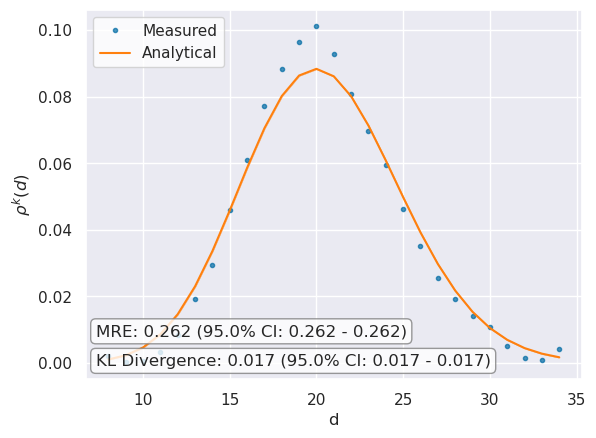

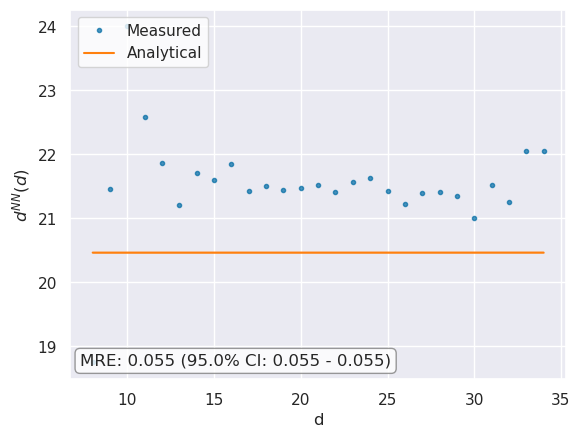

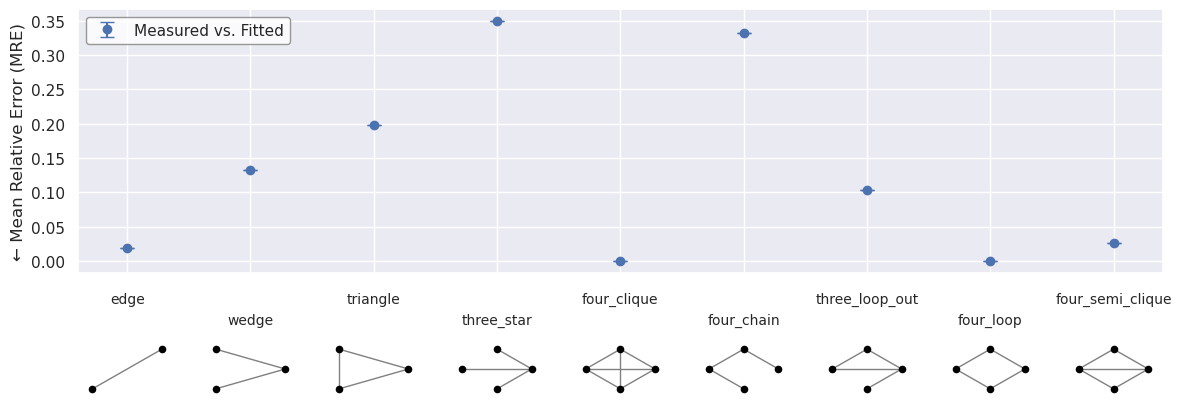

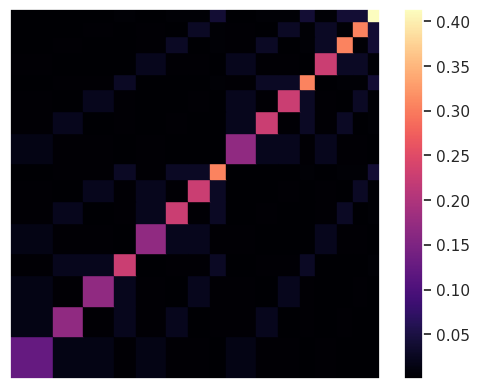

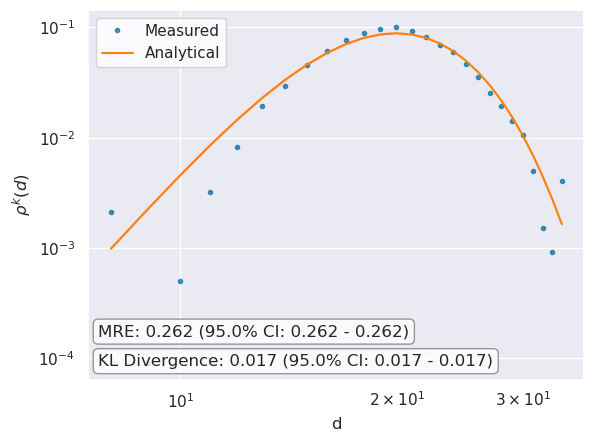

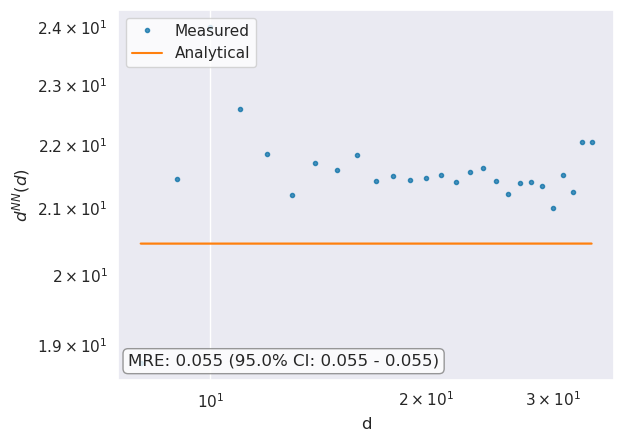

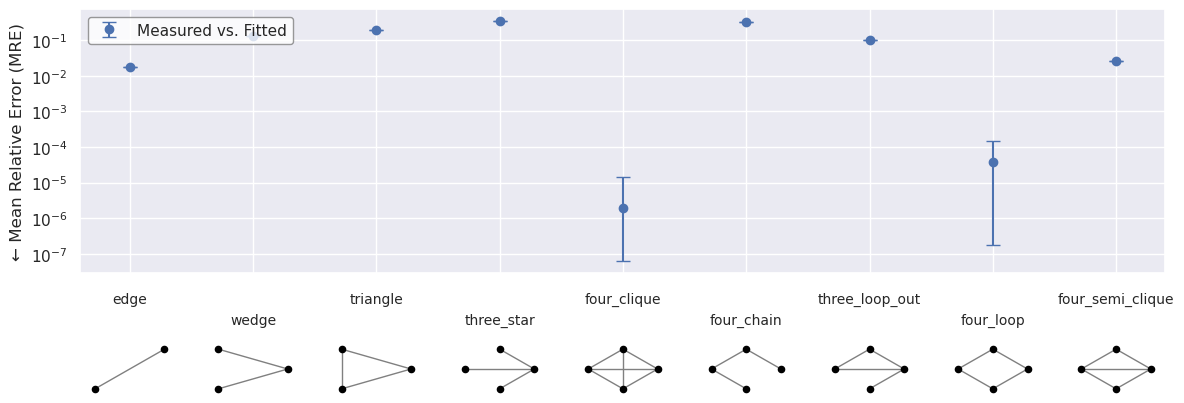

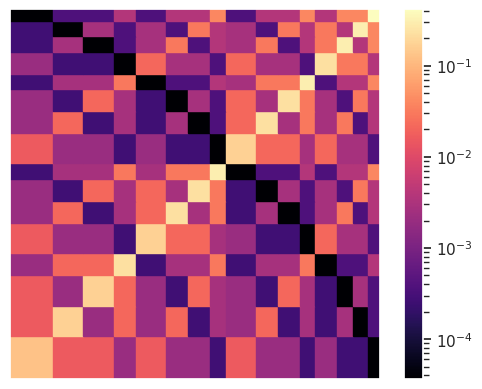

In [30]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/nested_sbm_plot_log.pdf"
)

# Generating variant graphs

Initializing...
0.0008552074432373047
Calculating betweenness...
Done.
Calculating node positions...
Done.


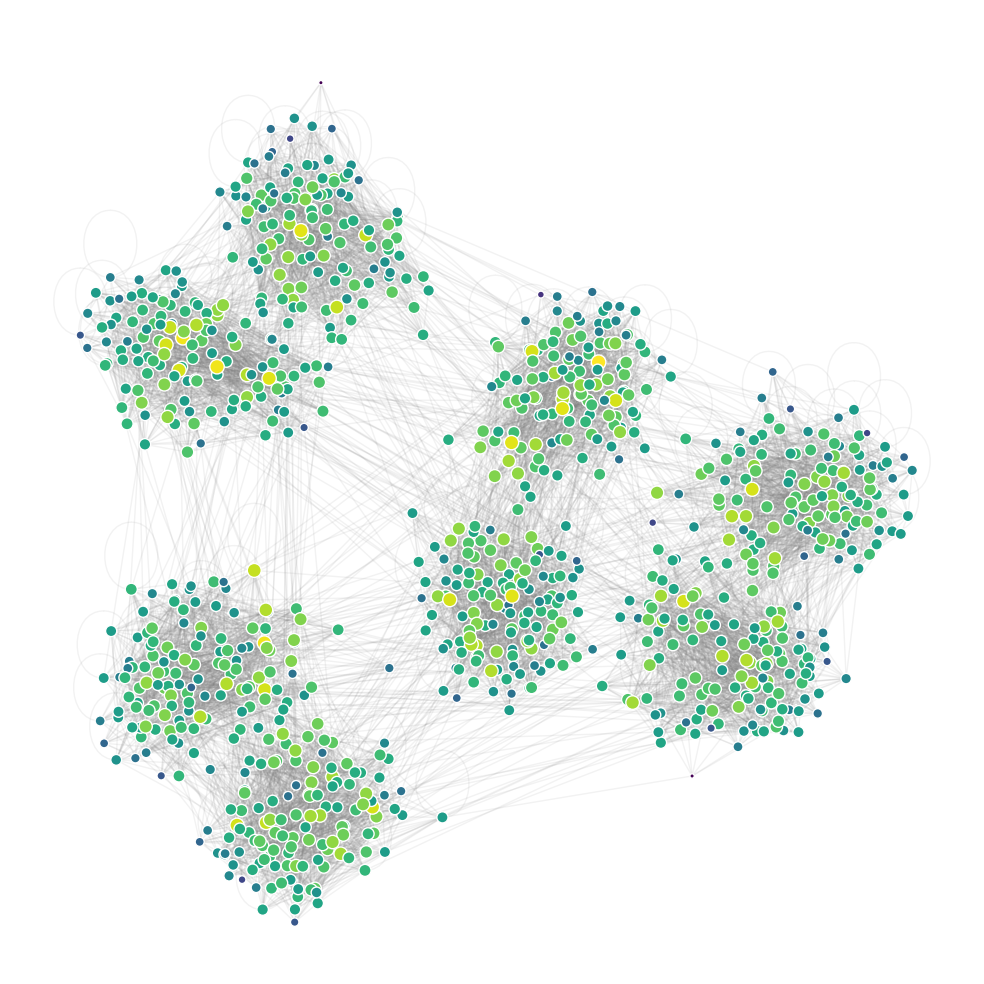

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 140.68it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 285.17it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 322.15it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


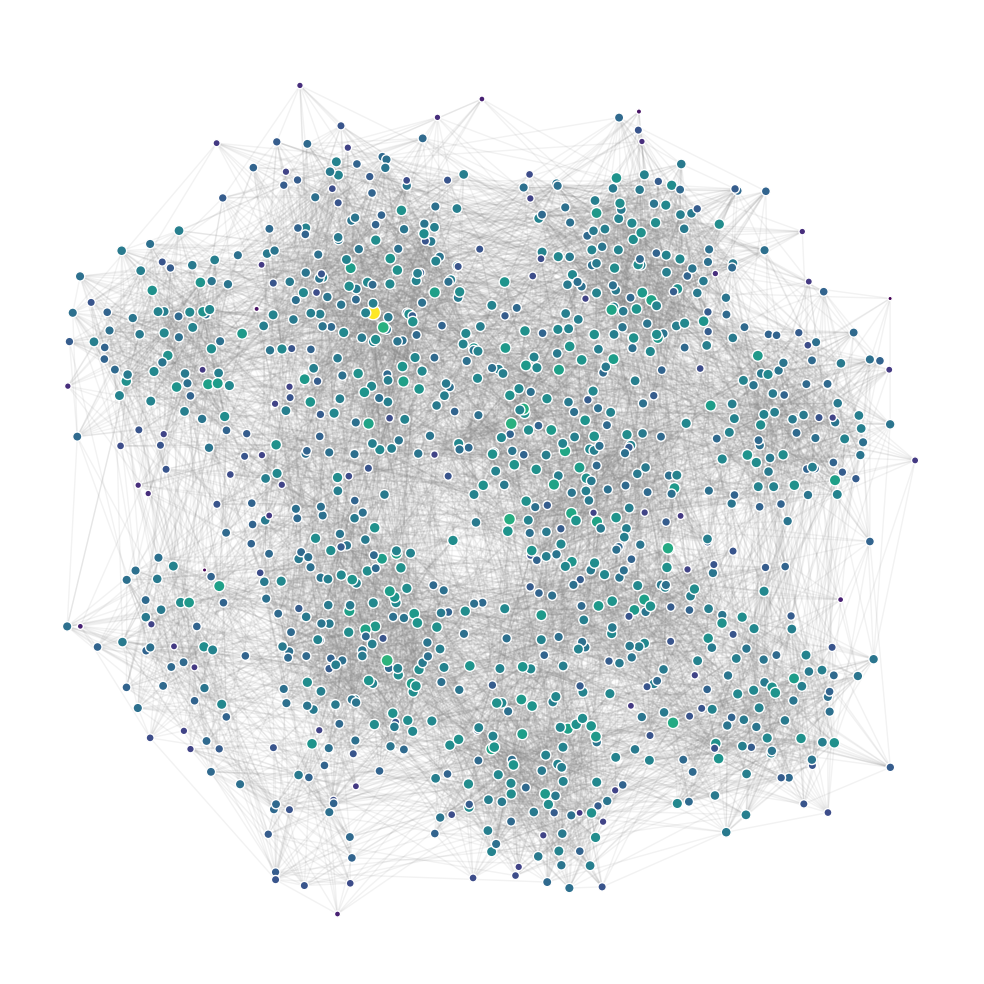

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 153.04it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 305.81it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 272.61it/s]


... (17 outputs left out)

100%|██████████| 32/32 [00:00<00:00, 268.71it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 250.95it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


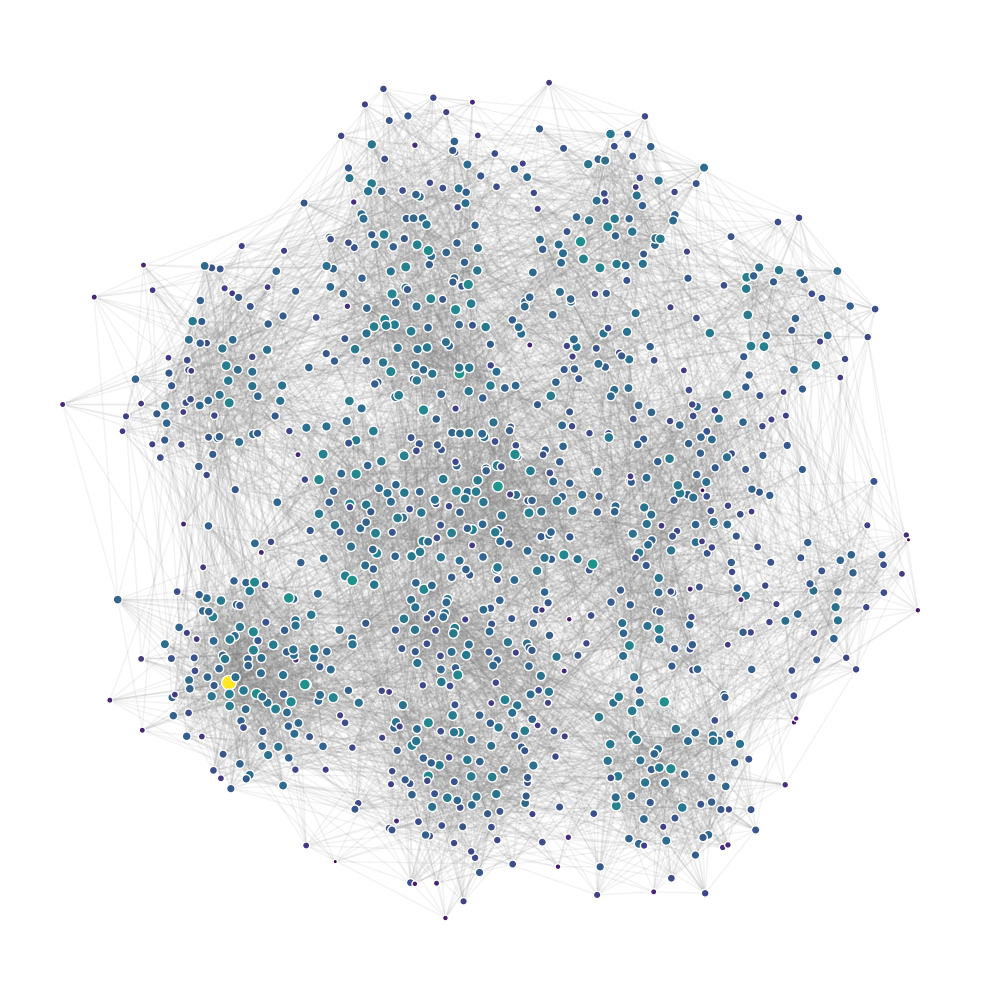

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:00<00:00, 165.07it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 245.22it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 280.33it/s]


... (7 outputs left out)

100%|██████████| 32/32 [00:00<00:00, 235.15it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 291.98it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


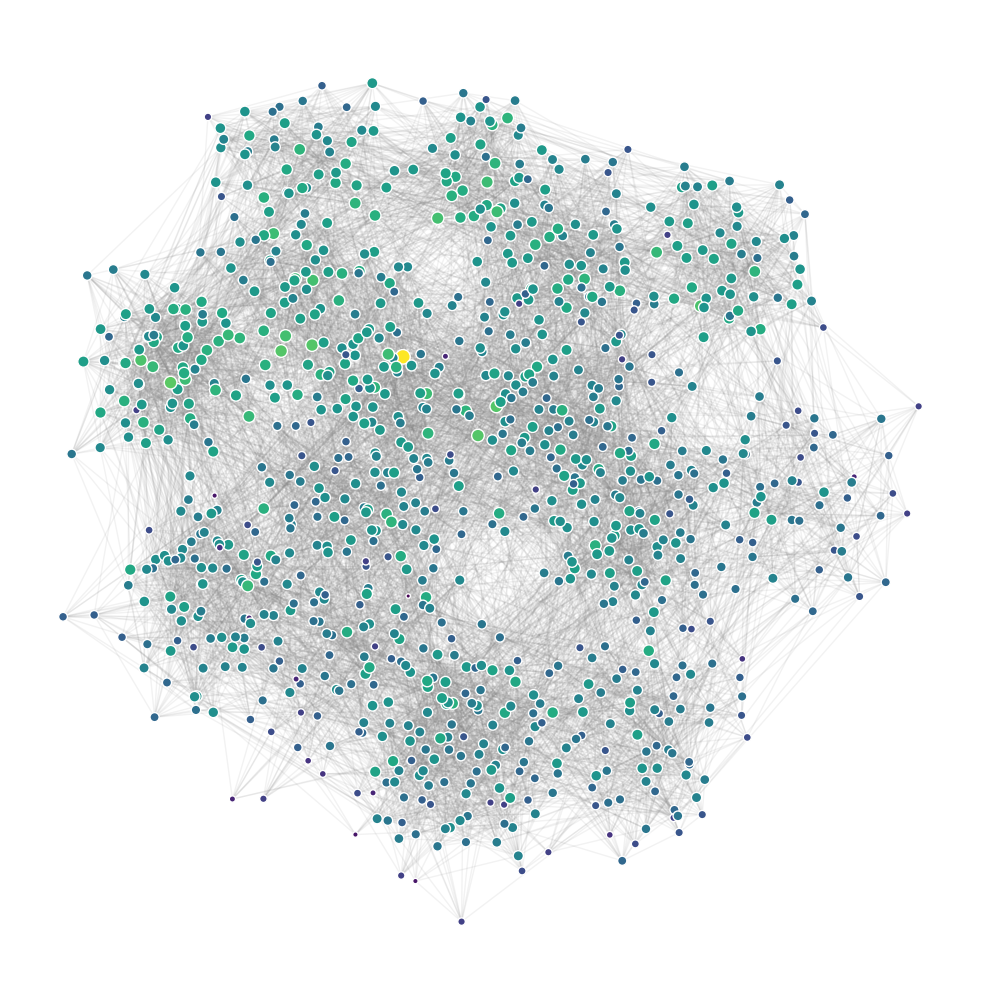

In [31]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.spring_layout,
        'figsize': (10,10),
        'filename':  "figures/nested_sbm_variants.pdf"
    },
    filename = "variant_networks/nested_sbm_variants.graphml"
)

In [ ]:
##